# Assignment 2 · Transfer Learning
## TensorFlow Flowers — готові результати й захист

Цей ноутбук відкриває **вже виконані експерименти**. Усі виводи збережено.
Можна натиснути `Run All`: він читає результати й показує рисунки, не навчає моделі
і не потребує TensorFlow. Для повторного навчання використайте ноутбук `01`.

| Критерій зі слайда 14 | Частка | Матеріали |
|---|---:|---|
| Confusion matrices | 60% | 9 raw, 9 normalized, матриці обраної CNN |
| Accuracy trend | 20% | 9 режимів заморожування, actual frozen layers, validation accuracy |
| Typical errors | 20% | частоти пар у всіх моделях, реальні фото, confidence, категорії причин |

In [1]:
from pathlib import Path
import json
import pandas as pd
import numpy as np
from IPython.display import display, Markdown, Image

# Працює з кореня проєкту або папки notebooks; абсолютних шляхів автора немає.
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "configs/full.json").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Розпакуйте весь проєкт і відкрийте ноутбук із його папки.")
NAMES = {"mobilenetv2": "MobileNetV2", "resnet50": "ResNet50", "vgg16": "VGG16",
         "logreg": "Logistic Regression", "svm": "SVM RBF", "randomforest": "Random Forest"}
def read_json(name):
    return json.loads((ROOT / name).read_text(encoding="utf-8"))
def table(name, **kwargs):
    return pd.read_csv(ROOT / "results/tables" / name, **kwargs)
def figure(name, width=1050):
    display(Image(filename=str(ROOT / "results/figures" / (name + ".png")), width=width))

config = read_json("configs/full.json")
quality = read_json("results/data_quality.json")
selected = read_json("results/selected_benchmark.json")
depth = read_json("results/selected_depth_test.json")
metrics = table("benchmark_metrics.csv")
print("Проєкт знайдено. Готові результати завантажено; навчання не запускається.")

Проєкт знайдено. Готові результати завантажено; навчання не запускається.


In [2]:
chosen = metrics.query("split == 'test'")
chosen = chosen[(chosen.extractor == selected["extractor"]) &
                (chosen.classifier == selected["classifier"])].iloc[0]
n_pairs = len(metrics.query("split == 'test'"))
policy = "усі шари" if depth["best_unfreeze_last"] >= depth["validation"]["total_backbone_layers"] \
    else f"last {depth['best_unfreeze_last']}"
display(Markdown(f"""
**Виконано:** {quality['raw_images']} фото, 5 класів, {n_pairs} класичних комбінацій; режимів заморожування CNN — {len(config['unfreeze_last'])}.

* Класична пара, обрана за validation: **{NAMES[selected['extractor']]} + {NAMES[selected['classifier']]}**.
  Test accuracy **{chosen.accuracy:.2%}**, macro-F1 **{chosen.macro_f1:.4f}**.
* CNN, обрана за validation: **MobileNetV2, {policy}**.
  Test accuracy **{depth['test']['accuracy']:.2%}**, macro-F1 **{depth['test']['macro_f1']:.4f}**.
* Дані: **{quality['split_counts']['train']} train / {quality['split_counts']['val']} validation /
  {quality['split_counts']['test']} test**. Seed 42.
* В архіві **36 PNG**, CSV із рішеннями для кожного тестового фото, збережені моделі,
  історії навчання, звіт і сценарій захисту.

Числа нижче є результатами фактичного запуску. Test не використовувався для вибору моделі.
"""))


**Виконано:** 3670 фото, 5 класів, 9 класичних комбінацій; режимів заморожування CNN — 9.

* Класична пара, обрана за validation: **ResNet50 + SVM RBF**.
  Test accuracy **89.84%**, macro-F1 **0.8971**.
* CNN, обрана за validation: **MobileNetV2, усі шари**.
  Test accuracy **91.83%**, macro-F1 **0.9171**.
* Дані: **2569 train / 550 validation /
  551 test**. Seed 42.
* В архіві **36 PNG**, CSV із рішеннями для кожного тестового фото, збережені моделі,
  історії навчання, звіт і сценарій захисту.

Числа нижче є результатами фактичного запуску. Test не використовувався для вибору моделі.


## 1. Дані й відтворюваність

Офіційний набір має єдину частину `train`; власні train/validation/test створено один раз.
Порядок класів узято з TFDS, він не алфавітний. Фото однакового SHA-256 залишені в одному split.
Три пари точних дублікатів збережені, одна пара має суперечливі мітки `roses` / `tulips`.
У цьому розбитті всі три пари потрапили до train. Майже однакові кадри окремо не усувалися.

In [3]:
display(pd.DataFrame({"label": range(5), "class_name": read_json("data/class_names.json")}))
display(table("split_counts.csv"))
display(table("duplicate_audit.csv")[["image_id", "class_name", "split", "conflicting_labels"]])
print("Manifest SHA-256:", quality["manifest_sha256"])

Manifest SHA-256: a10282424e8d9cd6e5097494357155ee29721f266ed81f409dbe548d3c255893


,label,class_name
0,0,dandelion
1,1,daisy
2,2,tulips
3,3,sunflowers
4,4,roses


,class_name,train,val,test
0,dandelion,628,135,135
1,daisy,443,95,95
2,tulips,559,120,120
3,sunflowers,490,104,105
4,roses,449,96,96


,image_id,class_name,split,conflicting_labels
0,flower_01651,roses,train,True
1,flower_02240,sunflowers,train,False
2,flower_02267,sunflowers,train,False
3,flower_02268,sunflowers,train,False
4,flower_02269,sunflowers,train,False
5,flower_03120,tulips,train,True


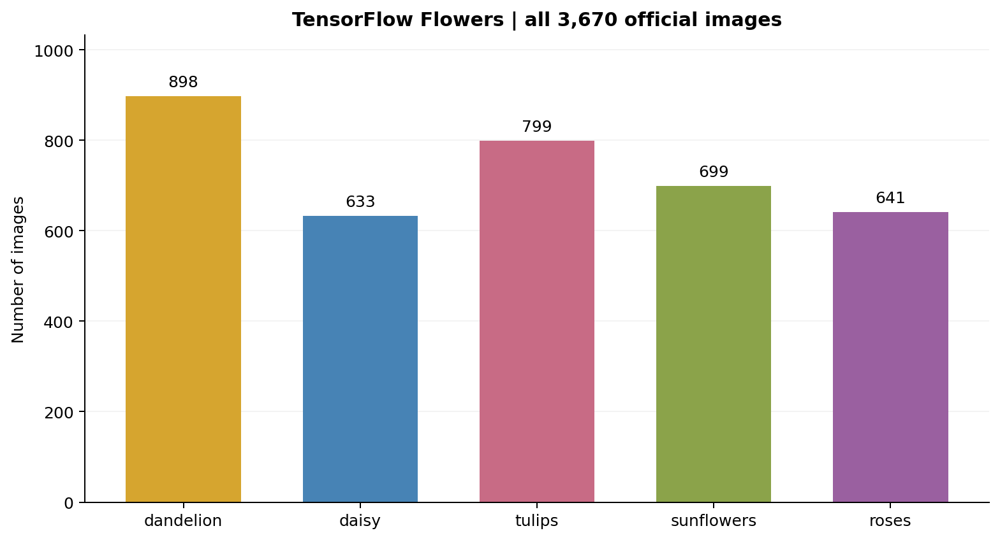

In [4]:
figure("eda_class_counts")
figure("eda_split_distribution")

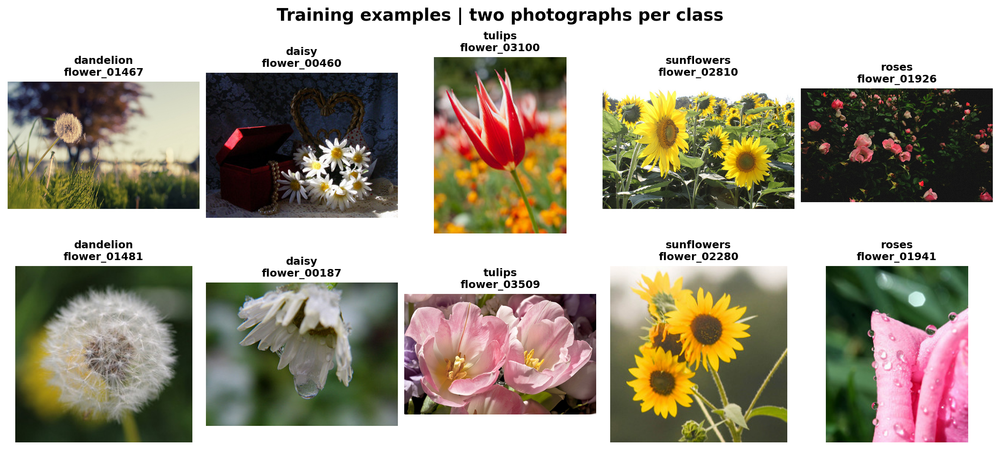

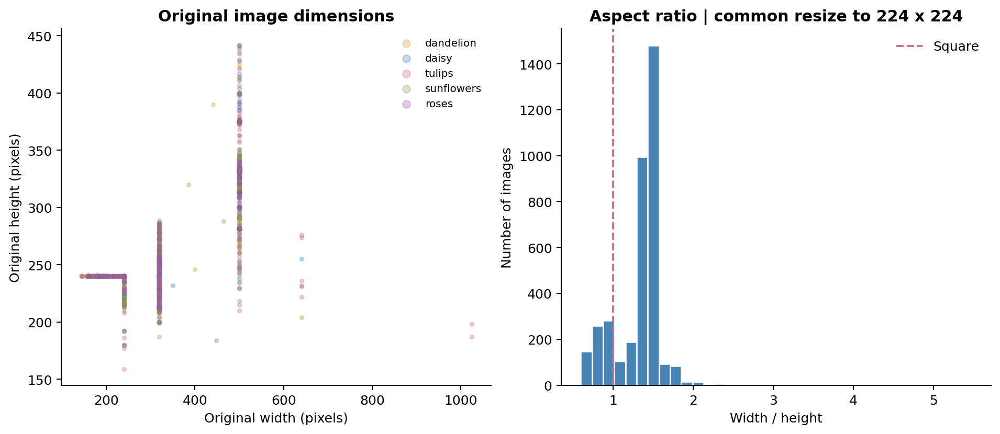

In [5]:
figure("eda_examples", 1200)
figure("eda_dimensions")

## 2. Benchmark: 3 екстрактори × 3 класифікатори = 9 пар

ImageNet CNN працює як незмінний екстрактор: `include_top=False`, Global Average Pooling.
MobileNetV2 дає 1280 ознак, ResNet50 — 2048, VGG16 — 512. VGG16 додано, бо саме VGG названо на слайді.
Logistic Regression і SVM навчаються в Pipeline зі StandardScaler; scaler бачить тільки train.
Random Forest не масштабується. Моделі й гіперпараметри визначені заздалегідь, Grid Search на test не проводився.

**Правило вибору:** найбільший validation macro-F1, потім validation accuracy.
Після фіксації переможця показано test для всіх 9 заздалегідь заданих кандидатів.
Найвища test-цифра серед кандидатів не змінює зафіксований вибір.

In [6]:
comparison = metrics.pivot(index=["extractor", "classifier"], columns="split", values=["accuracy", "macro_f1"])
display(comparison.round(4))
print("Вибір за validation:", NAMES[selected["extractor"]], "+", NAMES[selected["classifier"]])

Вибір за validation: ResNet50 + SVM RBF


accuracy         macro_f1        
split                        test     val     test     val
extractor   classifier                                    
mobilenetv2 logreg         0.8857  0.8873   0.8839  0.8840
            randomforest   0.8639  0.8782   0.8619  0.8757
            svm            0.9111  0.9036   0.9097  0.9021
resnet50    logreg         0.9111  0.9036   0.9091  0.9012
            randomforest   0.9002  0.9055   0.8989  0.9038
            svm            0.8984  0.9091   0.8971  0.9071
vgg16       logreg         0.8584  0.8618   0.8553  0.8591
            randomforest   0.8530  0.8655   0.8497  0.8646
            svm            0.8548  0.8655   0.8513  0.8644

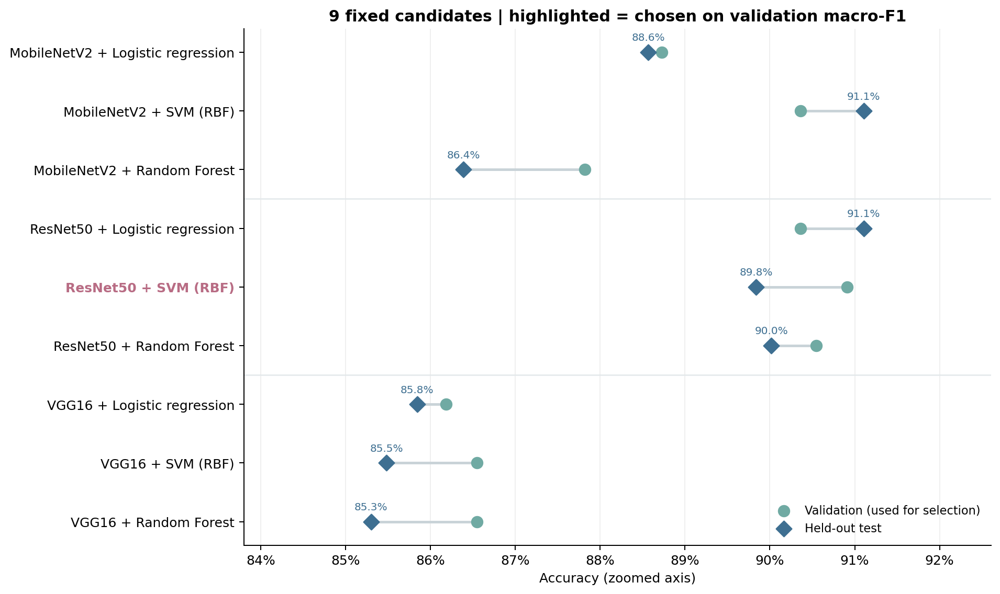

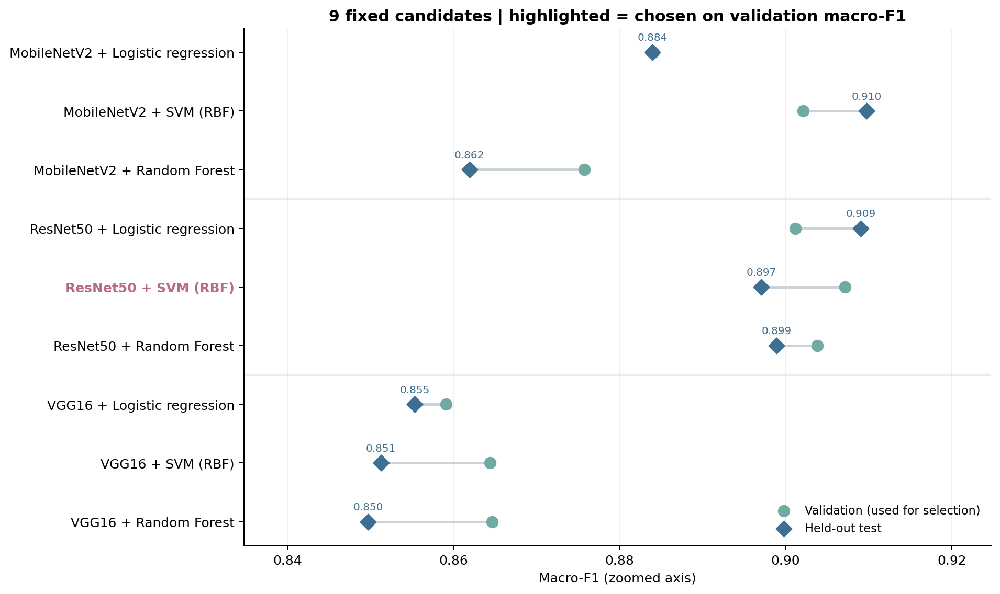

In [7]:
figure("benchmark_accuracy")
figure("benchmark_macro_f1")

### t-SNE ознак (візуалізація, як на слайді 14)

Тестові ознаки кожної CNN проєктуються у 2D без використання міток; колір — справжній клас.
Компактні кластери ілюструють локальні сусідства у 2D; це не доказ роздільності в початковому просторі ознак.
Кружками позначено тестові помилки обраної класичної пари. Їхнє положення в t-SNE не доводить причину помилки.

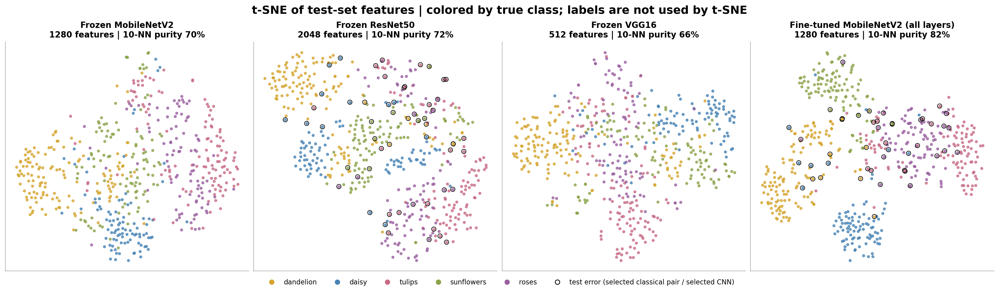

In [8]:
figure("feature_tsne", 1400)

## 3. Матриці помилок — 60% критеріїв

Рядок — істинний клас, стовпець — рішення моделі. Діагональ показує правильні прогнози.
У raw-матриці значення є кількостями; у normalized кожен рядок ділиться на свою суму,
тому діагональ є recall класу. У всіх raw-матриць одна шкала кольору, normalized — 0…100%.
Окремі 18 зображень і відповідні CSV збережені в `results/figures` та `results/tables`.

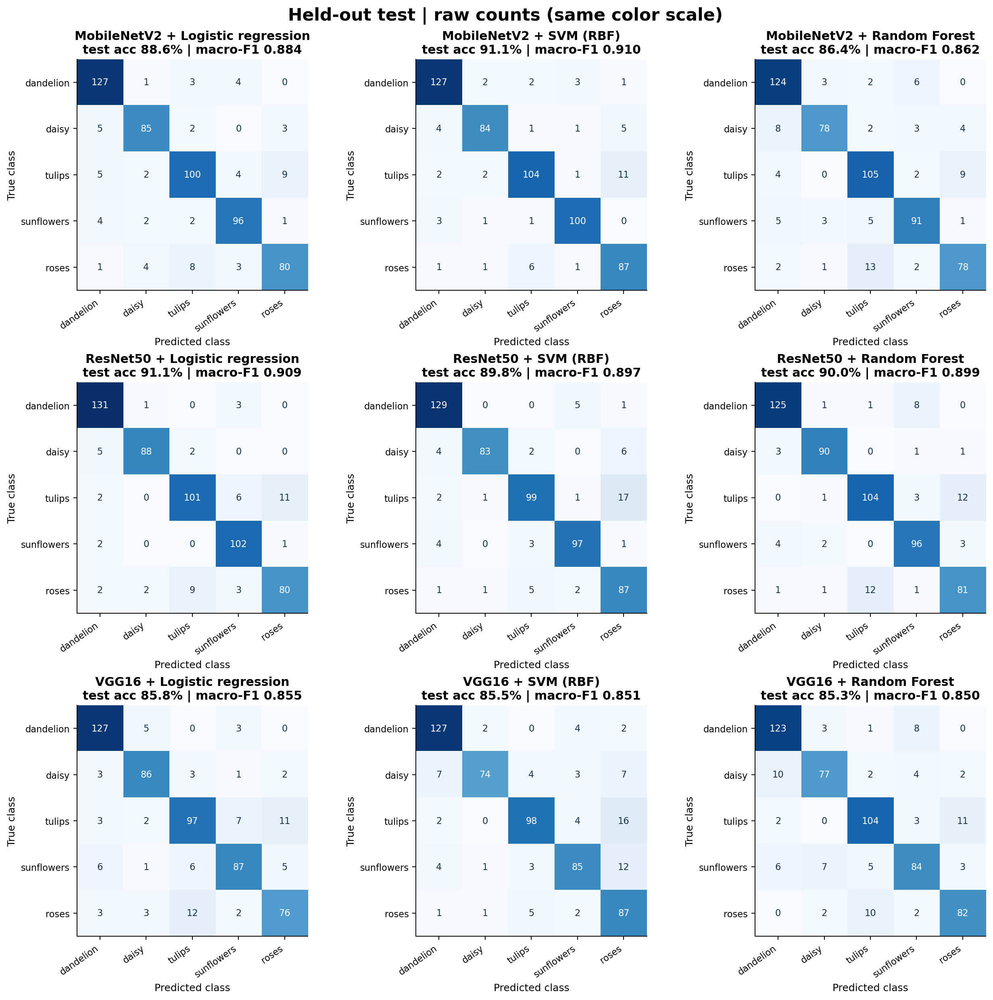

In [9]:
figure("confusion_raw_grid", 1400)

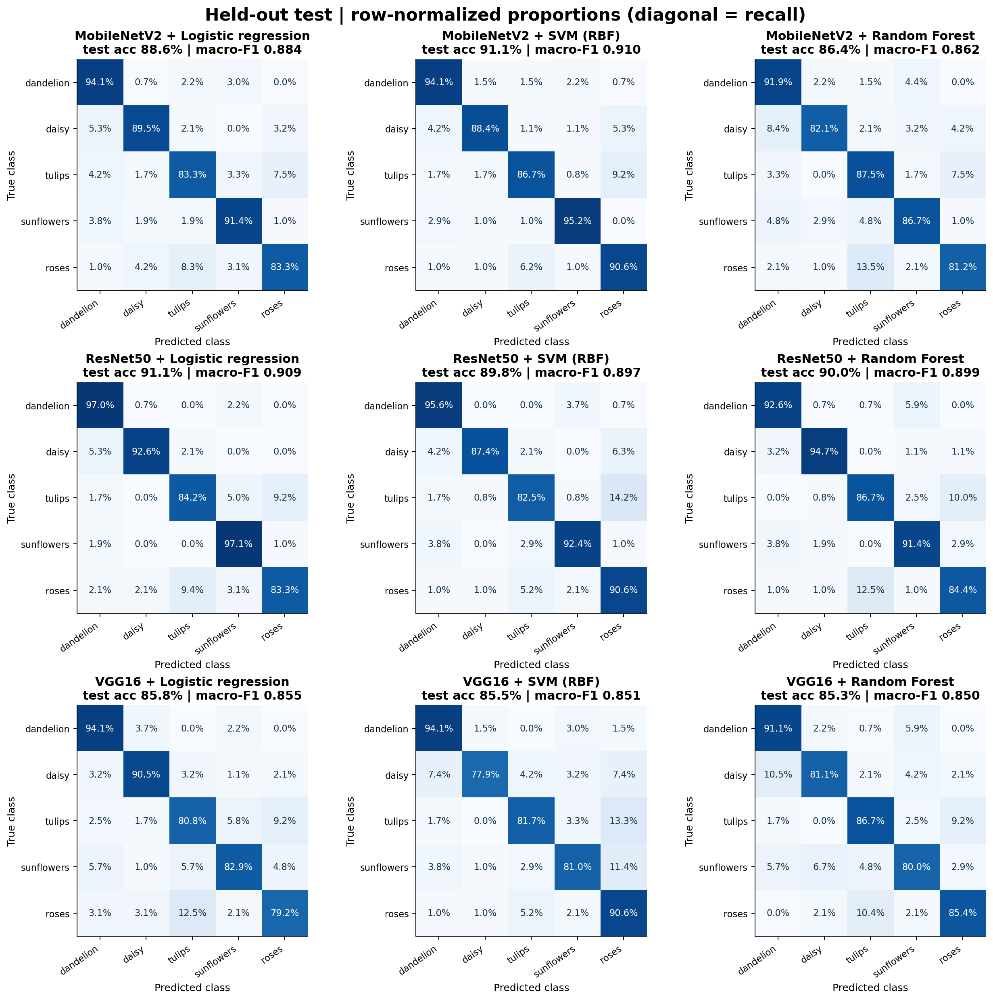

In [10]:
figure("confusion_normalized_grid", 1400)

In [11]:
key = selected["extractor"] + "_" + selected["classifier"]
print("Обрана пара:", NAMES[selected["extractor"]], "+", NAMES[selected["classifier"]])
display(table("confusion_" + key + ".csv", index_col=0))
display(table("classification_report_" + key + ".csv", index_col=0).round(4))

Обрана пара: ResNet50 + SVM RBF


,dandelion,daisy,tulips,sunflowers,roses
dandelion,129,0,0,5,1
daisy,4,83,2,0,6
tulips,2,1,99,1,17
sunflowers,4,0,3,97,1
roses,1,1,5,2,87


,precision,recall,f1-score,support
dandelion,0.9214,0.9556,0.9382,135.0000
daisy,0.9765,0.8737,0.9222,95.0000
tulips,0.9083,0.8250,0.8646,120.0000
sunflowers,0.9238,0.9238,0.9238,105.0000
roses,0.7768,0.9062,0.8365,96.0000
accuracy,0.8984,0.8984,0.8984,0.8984
macro avg,0.9014,0.8969,0.8971,551.0000
weighted avg,0.9033,0.8984,0.8990,551.0000


## 4. Залежність accuracy від глибини заморожених шарів — 20% критеріїв

Одна початкова голова після 3 warm-up епох; далі максимум 6 епох з Adam 1e-5.
Режими: розморожено останні 0, 10, 20, 35, 50, 75, 100, 115, 155 шарів MobileNetV2 (155 = усі шари).
Усі 52 BatchNorm frozen та inference. Режими використовують ті самі дані й перестановки train.
EarlyStopping відстежує val loss, patience=2; вимірювання — **після відновлення мінімуму val loss**.

`unfreeze_last` — ширина кінцевого вікна шарів, а не число навчуваних параметризованих шарів.
На осі X — фактичне число frozen шарів у backbone, включно з BatchNorm та шарами без ваг.
Додатково наведено число навчуваних шарів із вагами та число trainable параметрів.

Для прискорення незмінний префікс обчислено один раз у float32; trainable суфікс донавчається.
Враховано residual-ребра через межу префікса. Числова еквівалентність перевірена до й після fit.
Аугментація не застосовувалася. Можна виконати повну CNN без кешу через конфігурацію.

,unfreeze_last,frozen_layers,trainable_layer_flags,weighted_trainable_layers,trainable_backbone_params,epochs_run,restored_epoch,val_accuracy,val_macro_f1
0,0,155,0,0,0,6,4,0.8909,0.8887
1,10,148,7,3,725440,6,6,0.9036,0.9009
2,20,142,13,6,1041280,6,6,0.9055,0.9032
3,35,132,23,12,1608064,4,2,0.9055,0.9034
4,50,122,33,16,1779136,4,2,0.9127,0.9107
5,75,105,50,25,2012416,4,2,0.9127,0.9112
6,100,89,66,33,2131648,6,5,0.9218,0.9204
7,115,79,76,38,2157952,4,2,0.9109,0.9094
8,155,52,103,52,2189760,6,5,0.9255,0.9238


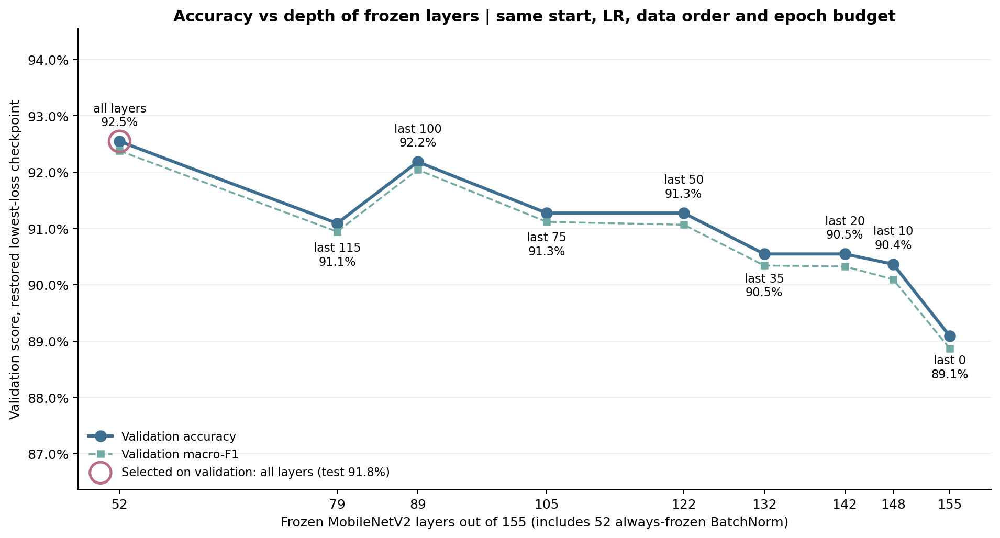

In [12]:
freeze = table("freeze_depth_validation.csv").sort_values("frozen_layers", ascending=False)
display(freeze[["unfreeze_last", "frozen_layers", "trainable_layer_flags", "weighted_trainable_layers", "trainable_backbone_params", "epochs_run", "restored_epoch", "val_accuracy", "val_macro_f1"]].round(4).reset_index(drop=True))
figure("freeze_depth_accuracy_trend")

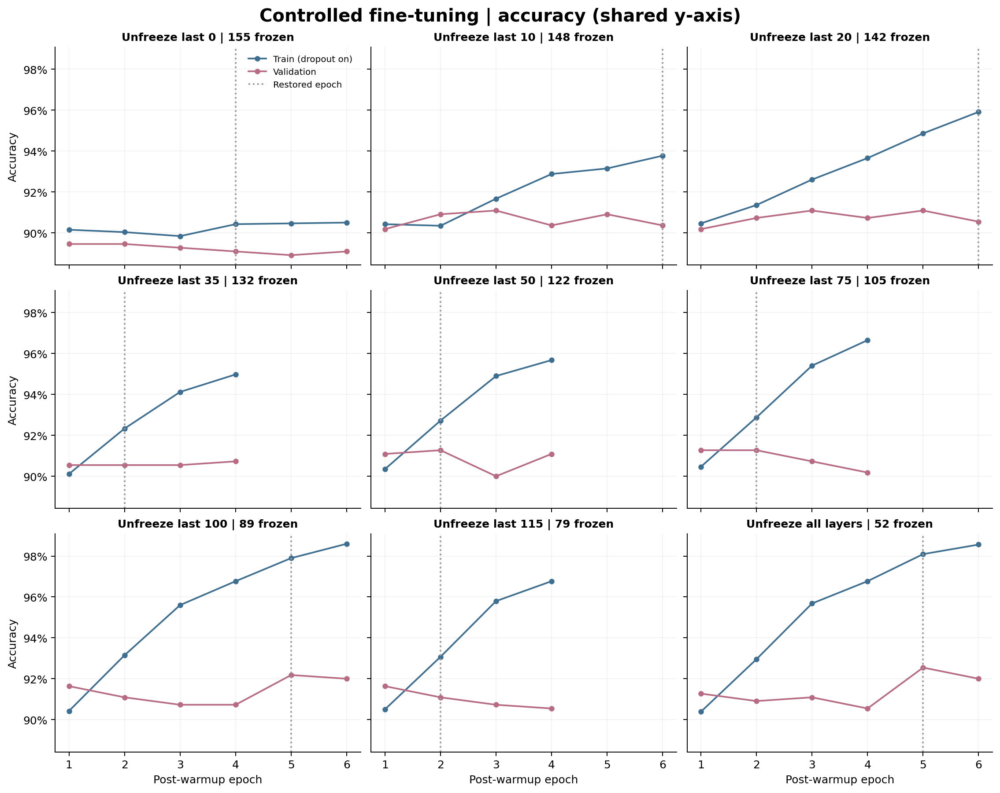

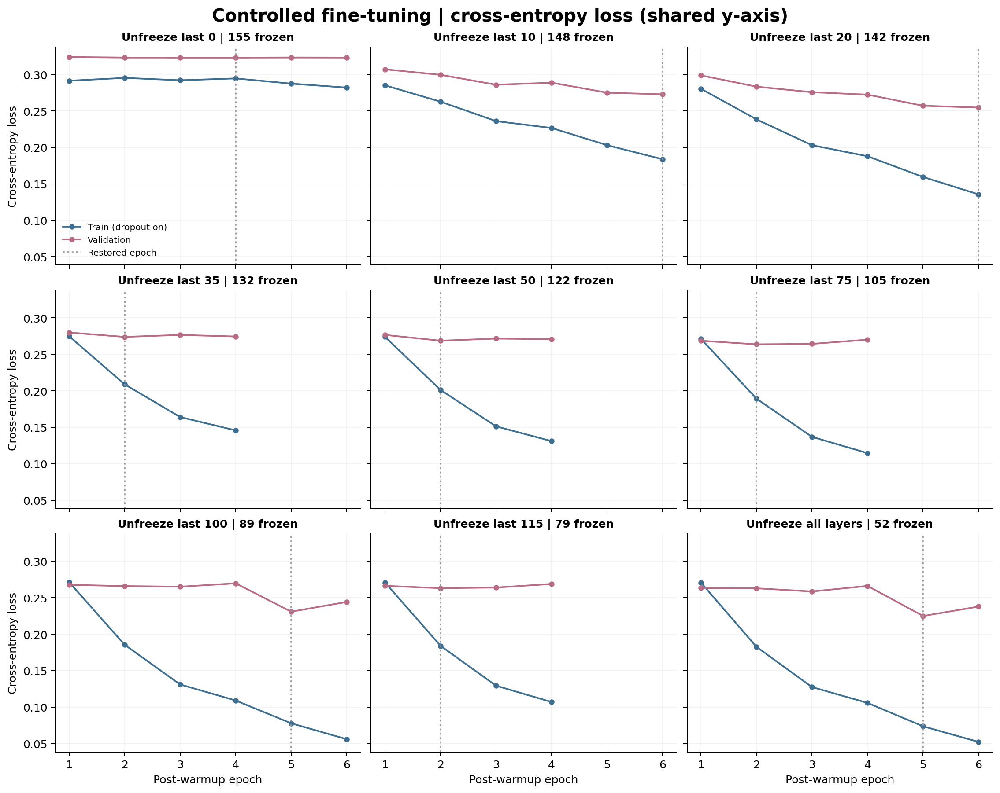

In [13]:
figure("freeze_learning_accuracy", 1300)
figure("freeze_learning_loss", 1300)

**Вибрана політика:** усі шари. Test accuracy: **91.83%**, macro-F1: **0.9171**.

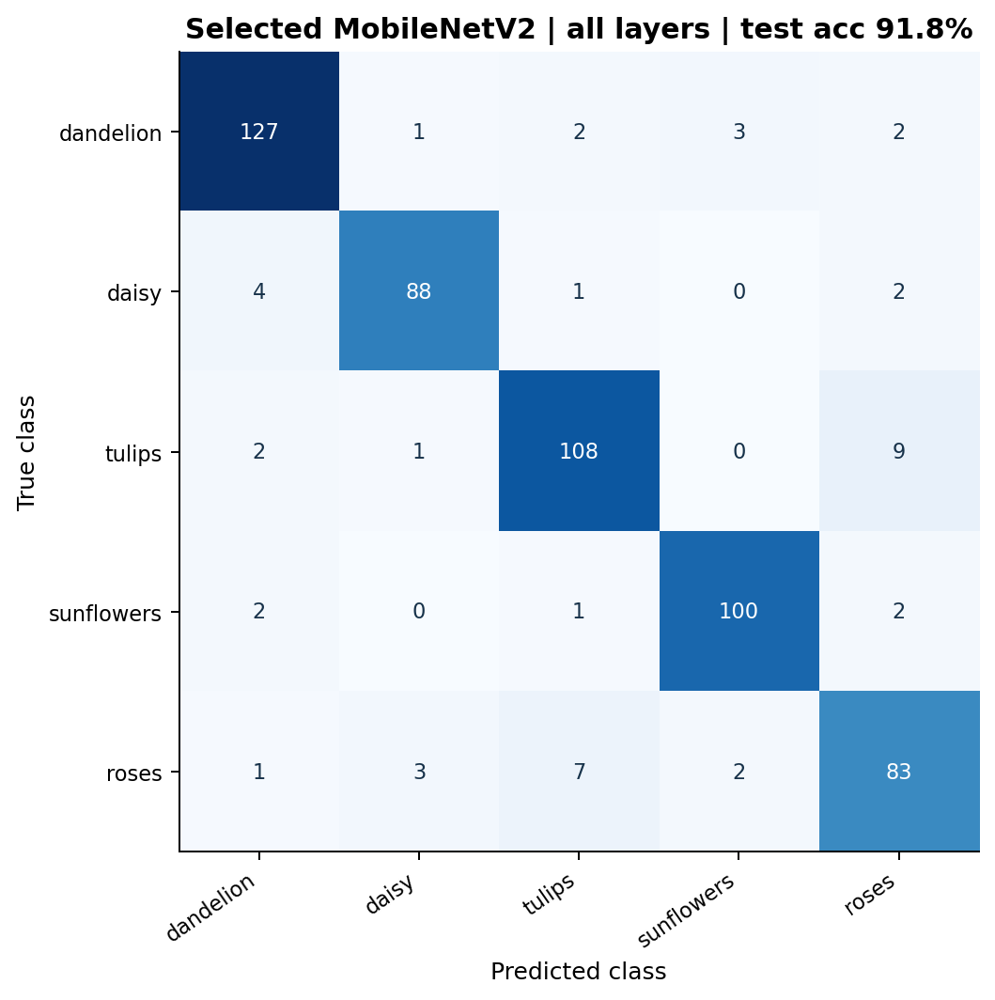

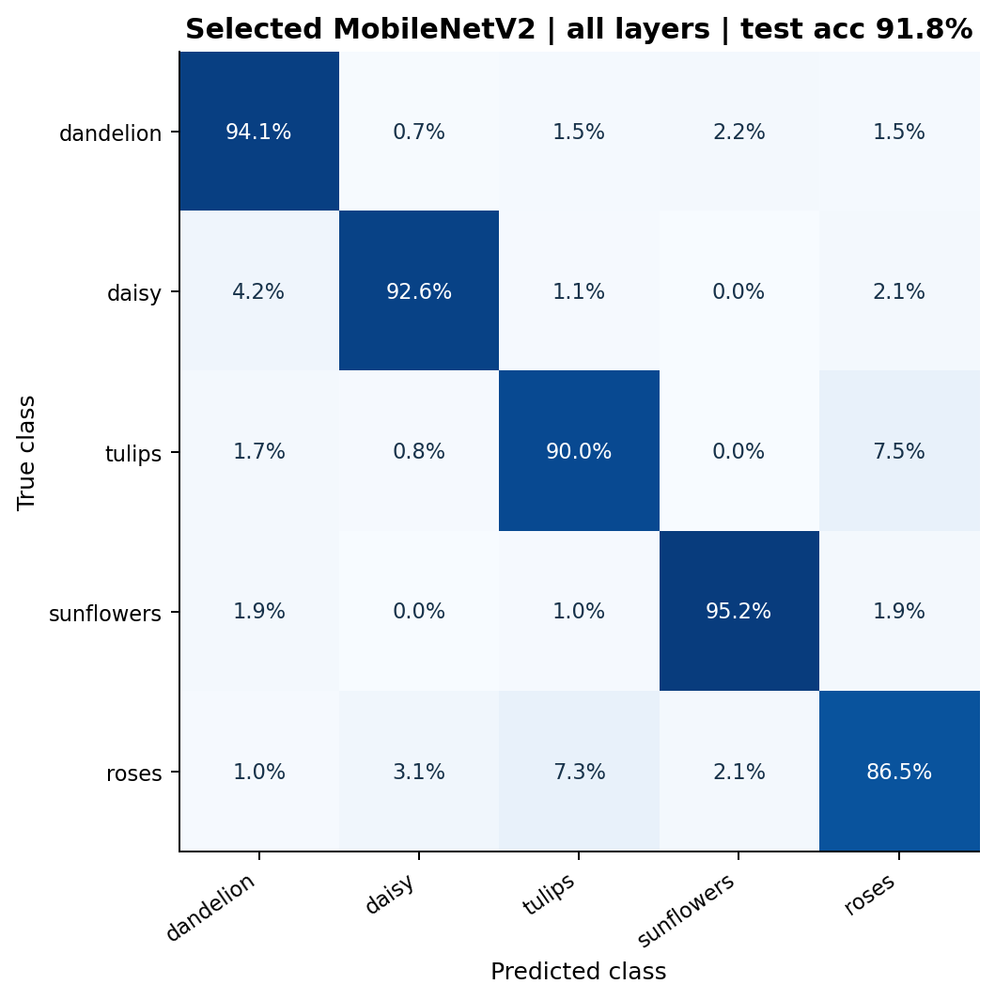

In [14]:
display(Markdown(f"**Вибрана політика:** {policy}. "
                 f"Test accuracy: **{depth['test']['accuracy']:.2%}**, "
                 f"macro-F1: **{depth['test']['macro_f1']:.4f}**."))
figure("freeze_best_confusion", 800)
figure("freeze_best_confusion_normalized", 800)

## 5. Характерні помилки — 20% критеріїв

Спочатку частоти: які направлені пари «істинний → прогноз» найчастіші в обраної моделі,
і чи повторюються ті самі клітинки в усіх класичних пар та в обраної CNN (тоді помилка систематична).
Галерея `typical_errors` показує до чотирьох фото для найчастіших пар,
`confident_errors` — найвпевненіші хибні рішення. Confidence є `predict_proba` саме класу,
повернутого `predict`; у SVM ці два правила не завжди мають один argmax.
Візуальні пояснення нижче є гіпотезами за переглянутими фото, а не доказом мотиву CNN.

,true_class,pred_class,count
0,tulips,roses,17
1,daisy,roses,6
2,dandelion,sunflowers,5
3,roses,tulips,5
4,daisy,dandelion,4
5,sunflowers,dandelion,4
6,sunflowers,tulips,3
7,daisy,tulips,2
8,roses,sunflowers,2
9,tulips,dandelion,2


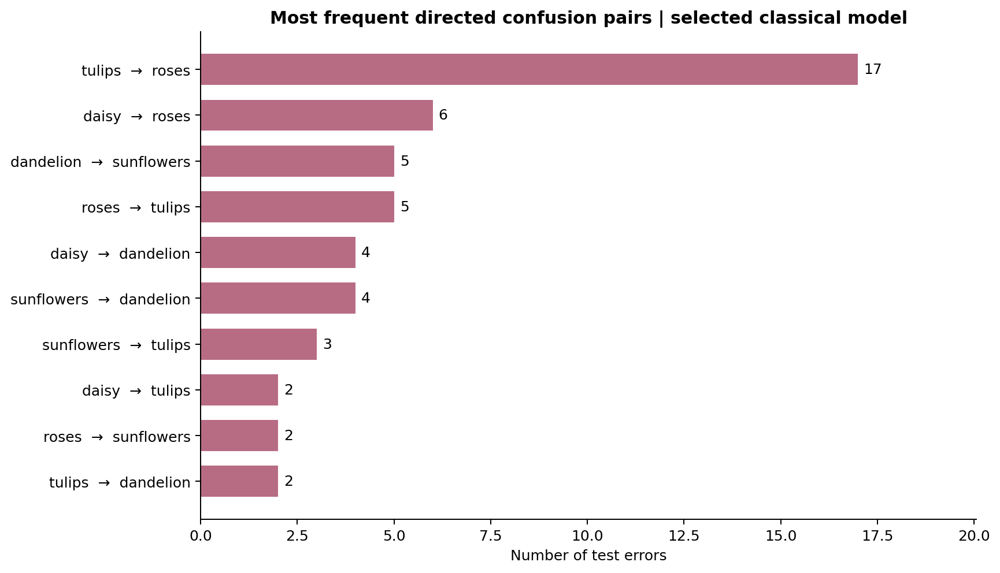

In [15]:
display(table("common_error_pairs.csv"))
figure("common_error_pairs")

,true_class,pred_class,mean_classical,min_classical,max_classical,selected_cnn
0,tulips,roses,11.89,9.0,17.0,9
1,roses,tulips,8.89,5.0,13.0,7
2,daisy,dandelion,5.44,3.0,10.0,4
3,dandelion,sunflowers,4.89,3.0,8.0,3
4,sunflowers,dandelion,4.22,2.0,6.0,2
5,tulips,sunflowers,3.44,1.0,7.0,0
6,daisy,roses,3.33,0.0,7.0,2
7,sunflowers,roses,3.00,0.0,12.0,2


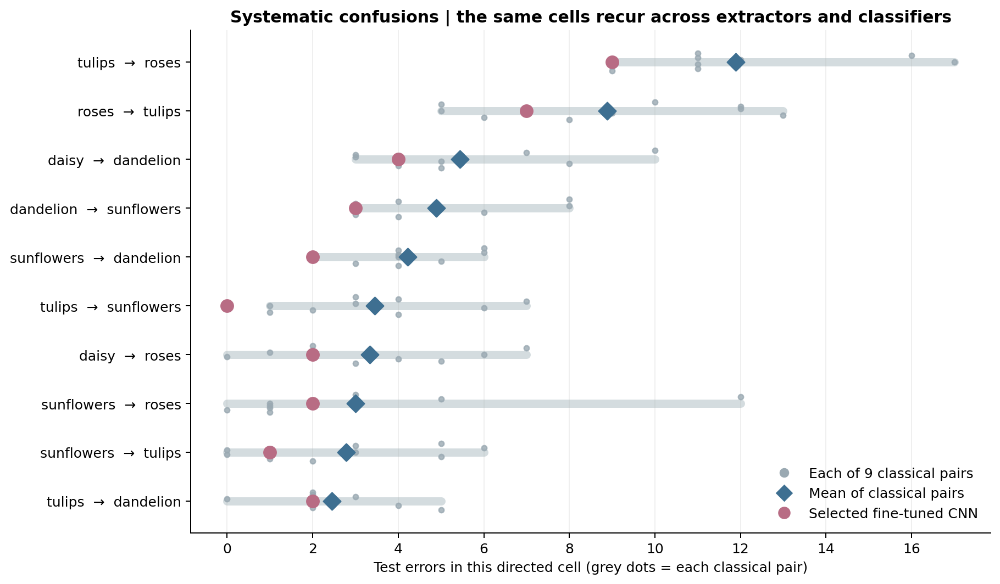

In [16]:
across = table("error_pairs_across_models.csv")
display(across[["true_class", "pred_class", "mean_classical", "min_classical", "max_classical", "selected_cnn"]].head(8).round(2))
figure("error_pairs_across_models")

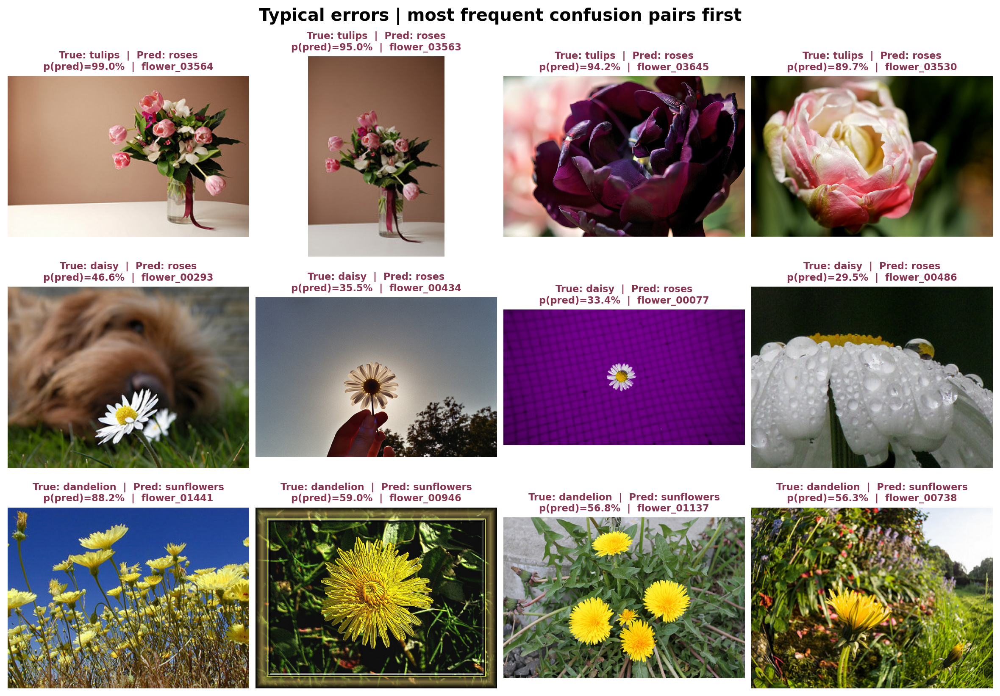

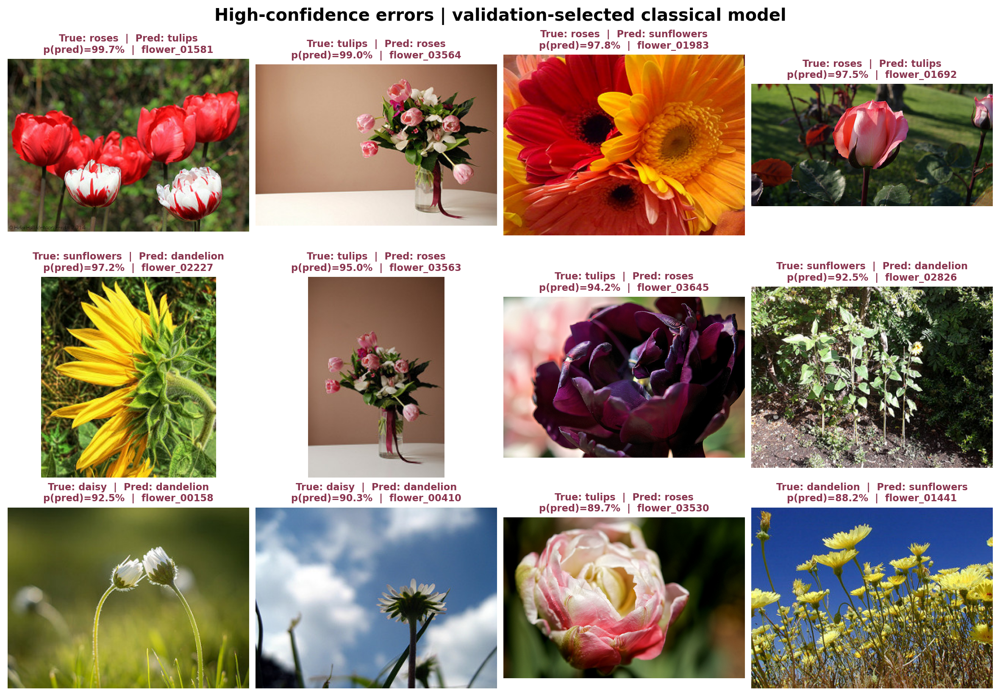

In [17]:
figure("typical_errors", 1300)
figure("confident_errors", 1300)

In [18]:
observations = table("error_observations_ua.csv")
display(observations.error_category.value_counts().rename("кількість фото"))
with pd.option_context("display.max_colwidth", None):
    display(observations[["image_id", "true_class", "pred_class", "error_category", "visible_observation", "possible_explanation"]])

error_category
Ракурс, світло або обробка фото    6
Малий обʼєкт / складний фон        3
Схожі класи                        3
Анотація / поза класом             3
Кілька видів у кадрі               2
Name: кількість фото, dtype: int64

,image_id,true_class,pred_class,error_category,visible_observation,possible_explanation
0,flower_03564,tulips,roses,Кілька видів у кадрі,"Букет у вазі: рожеві тюльпани разом із білими квітами іншого виду, зеленню та стрічкою; офіційна мітка tulips.","Кілька видів у кадрі, а компактні рожеві головки в центрі букета за формою схожі на троянди. Мітка tulips виглядає правдоподібною, тож це помилка моделі."
1,flower_03563,tulips,roses,Кілька видів у кадрі,"Той самий букет і фон, що у flower_03564, інше кадрування (вертикальний кадр).",Майже-дублікат попереднього фото: два кадри не є незалежними доказами; помилка повторюється з тієї самої причини.
2,flower_03645,tulips,roses,Схожі класи,Крупний план темно-фіолетової квітки з багатьма перекритими пелюстками.,Багатошарова форма пелюсток і відсутність повного силуету можуть створювати схожість із roses.
3,flower_03530,tulips,roses,Схожі класи,"Світлі щільно розташовані пелюстки з рожевими краями, видно одну головку квітки.","Візуальна схожість махрового бутона з трояндою; це інтерпретація фото, а не доказ механізму CNN."
4,flower_00293,daisy,roses,Малий обʼєкт / складний фон,Біла ромашка внизу кадру; більшу частину зображення займає собака.,"Обʼєкт займає малу частку кадру, складний фон. Ймовірність рішення 46.6% показує невпевненість."
5,flower_00434,daisy,roses,"Ракурс, світло або обробка фото","Квітка на просвіт на тлі яскравого неба, у кадрі видно руку.",Контрове світло й незвичний контраст змінюють вигляд пелюсток.
6,flower_00077,daisy,roses,Малий обʼєкт / складний фон,Дрібна біла квітка на великому фіолетовому тлі з вираженою сітчастою фактурою.,Фон значно переважає за площею; квітка займає мало пікселів після resize.
7,flower_00486,daisy,roses,"Ракурс, світло або обробка фото",Дуже крупний обрізаний план білих пелюсток із краплями води; центр видно частково.,Обрізаний силует і незвичний ракурс ускладнюють розпізнавання виду.
8,flower_00946,dandelion,sunflowers,"Ракурс, світло або обробка фото",Жовта квітка на контрастному обробленому зображенні з декоративною рамкою.,"Змінені кольори, різкість і рамка відрізняються від типових природних фото."
9,flower_01581,roses,tulips,Анотація / поза класом,На фото чітко видно червоні та біло-червоні махрові тюльпани; офіційна мітка roses.,"Найімовірніше помилка офіційної мітки: модель назвала тюльпани з 99.7%, тобто тут «помилка» моделі може бути правильною відповіддю."


## 6. Перевірки, висновки та межі результату

Висновок стосується одного датасету, одного seed і одного split. Це не доказ універсальної
переваги одного екстрактора чи алгоритму. Присутні складні фони, ймовірний шум міток і
майже-дублікати. Різницю у кілька правильних фото не трактуємо як доведену статистичну перевагу.
Моделі не навчають клас «не квітка», не оцінюють повний ботанічний асортимент і не мають
зовнішньої перевірки калібрування впевненості.

In [19]:
audit = read_json("results/audit.json")
print("Статус:", audit["status"], "| перевірок:", len(audit["checks"]))
display(pd.DataFrame(audit["checks"])[["check", "passed"]])

Статус: passed | перевірок: 103


,check,passed
0,Official sample count,True
1,One subset per duplicate group,True
2,Five classes in every split,True
3,No shared content hashes: train/val,True
4,No shared content hashes: train/test,True
...,...,...
98,Depth 115: BatchNorm frozen,True
99,Depth 155: frozen weights unchanged,True
100,Depth 155: expected trainable updates,True
101,Depth 155: BatchNorm frozen,True


In [20]:
display(Markdown((ROOT / "report/CONCLUSIONS_UA.md").read_text(encoding="utf-8")))

# Висновки за фактичним запуском

1. Порівняно 9 пар екстрактор–класифікатор (3 CNN × 3 класифікатори) на 2569 train / 550 validation / 551 test. Розмір вектора ознак: MobileNetV2 — 1280, ResNet50 — 2048, VGG16 — 512. Єдине розбиття, масштабування лише на train й однакові метрики роблять порівняння узгодженим.

2. За validation macro-F1 вибрано **ResNet50 + SVM RBF**: validation accuracy **90.91%**, validation macro-F1 **0.9071**. Для цієї зафіксованої пари test accuracy становить **89.84%**, macro-F1 — **0.8971** (495 правильних із 551).

3. Найвищу test accuracy серед 9 фіксованих пар показали MobileNetV2 + SVM RBF та ResNet50 + Logistic Regression: **91.11%**. Цей описовий результат не використано для перевибору моделі; ranking на validation не зобовʼязаний повторитися на test. Середня accuracy validation / test за трьома класифікаторами: ResNet50 90.61% / 90.32%, MobileNetV2 88.97% / 88.69% та VGG16 86.42% / 85.54%. Середня accuracy за трьома екстракторами: SVM RBF 89.27% / 88.81%, Logistic Regression 88.42% / 88.51% та Random Forest 88.30% / 87.24%.

4. Accuracy trend: досліджено 9 режимів: від повністю замороженої MobileNetV2 (155 frozen, навчається лише голова) до розморожування всіх шарів, крім 52 BatchNorm (52 frozen). Validation accuracy змінюється від 89.09% до 92.55% (розмах 3.45 в. п.). Head-only дає 89.09%, найкращий режим («усі шари») — 92.55% (+3.45 в. п.). Загальна тенденція: що більше шарів розморожено, то вища точність, але крива немонотонна: перехід last 100 → last 115 знижує accuracy на 1.09 в. п. (6 фото). Різниці в кілька фото на validation з 550 зображень не слід переінтерпретувати.

5. Обрана за validation CNN (усі шари, checkpoint епохи **5**) дала **91.83%** test accuracy та **0.9171** macro-F1 (506 правильних із 551). Серед 9 класичних пар максимум був 502/551. Це результати одного split, формально статистичну перевагу не доведено.

6. Найчастіша помилка обраної класичної пари: **tulips → roses, 17 фото**, тобто 17/120 = **14.17%** цього класу; зворотний напрям — 5. Ця ж клітинка є найчастішою й у середньому по всіх 9 класичних парах (11.9 помилки; від 9 до 17), а в обраної CNN — 9. Отже, плутанина tulips/roses систематична, а не випадкова для одного алгоритму.

7. У 17 переглянутих хибних прогнозах виділено причини: ракурс, світло або обробка фото (6), малий обʼєкт / складний фон (3), схожі класи (3), анотація / поза класом (3) та кілька видів у кадрі (2). Частина найвпевненіших «помилок» — це, найімовірніше, неточні офіційні мітки або квіти поза пʼятьма класами; модель без reject-класу все одно вибирає один із пʼяти.

8. Три пари точних дублікатів не перетинають split; одна пара з різними мітками збережена в train. Обмеження: один seed і split, майже-дублікати не усувалися вичерпно, можливі помилки анотації, немає зовнішнього test і reject-класу.


## 7. План захисту на 8–10 хвилин

1. **Учасник 1:** дані, split, перевірка дублікатів, MobileNetV2 і VGG16, t-SNE — 2–3 хв.
2. **Учасник 2:** ResNet50, SVM, warm-up і контроль глибини заморожування, графік — 3 хв.
3. **Учасник 3:** RF, порівняння пар, матриці, частоти помилок, конкретні фото — 3–4 хв.

Повний текст виступу та запитання: `report/DEFENSE_UA.md`.
Відповідність умовам: `report/REQUIREMENTS_CHECKLIST.md`.

## Джерела

* Надана презентація `Labs.pdf`, слайд 14, Transfer learning:
  https://github.com/dryabokon/Docs/blob/master/ML/Labs.pdf
* TFDS TensorFlow Flowers: https://www.tensorflow.org/datasets/catalog/tf_flowers
* Код датасету і класи:
  https://github.com/tensorflow/datasets/blob/master/tensorflow_datasets/datasets/tf_flowers/tf_flowers_dataset_builder.py
* Keras Transfer learning: https://keras.io/guides/transfer_learning/
* MobileNetV2: https://keras.io/api/applications/mobilenet/mobilenet_models/
* ResNet: https://keras.io/api/applications/resnet/
* VGG16: https://keras.io/api/applications/vgg/
* Метрики: https://scikit-learn.org/stable/modules/model_evaluation.html
* t-SNE: https://scikit-learn.org/stable/modules/generated/sklearn.manifold.TSNE.html

Атрибуція фото: `data/FLOWERS_LICENSE.txt`. Ваги ImageNet — Keras Applications.